In [1]:
import os, glob, random, itertools, time, io, base64, json
import numpy as np, torch, torch.nn as nn
from PIL import Image
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.utils import make_grid, save_image

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# ---- paths ----
DATA_ROOT  = '/kaggle/input/person-face-sketches'
if not os.path.exists(DATA_ROOT):
    cands = glob.glob('/kaggle/input/*')
    print('Inputs found:', cands); DATA_ROOT = cands[0]
WORK       = '/kaggle/working'
CKPT_DIR   = f'{WORK}/checkpoints'
SAMPLE_DIR = f'{WORK}/samples'
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(SAMPLE_DIR, exist_ok=True)

# ---- hyperparameters (tune these) ----
IMG_SIZE     = 128     # paper uses 256; use 256 + N_RES=9 if GPU time allows
N_RES        = 6       # 6 res-blocks for 128px, 9 for 256px
BATCH        = 4       # paper uses 1
LR           = 2e-4
BETA1, BETA2 = 0.5, 0.999
EPOCHS       = 50
DECAY_START  = 25      # LR constant until here, then linear decay to 0
LAMBDA_CYC   = 10.0
LAMBDA_ID    = 5.0
POOL_SIZE    = 50

Device: cuda
Inputs found: ['/kaggle/input/datasets']


DATA_ROOT = /kaggle/input/datasets/almightyj/person-face-sketches
val/photos -> 1000 files
val/sketches -> 1000 files
test/photos -> 679 files
test/sketches -> 679 files
train/photos -> 20655 files
train/sketches -> 20655 files
Found -> Train photos/sketches: 20655/20655 | Test: 679/679
Using -> Train A/B: 3000/3000 | Test A/B: 200/200


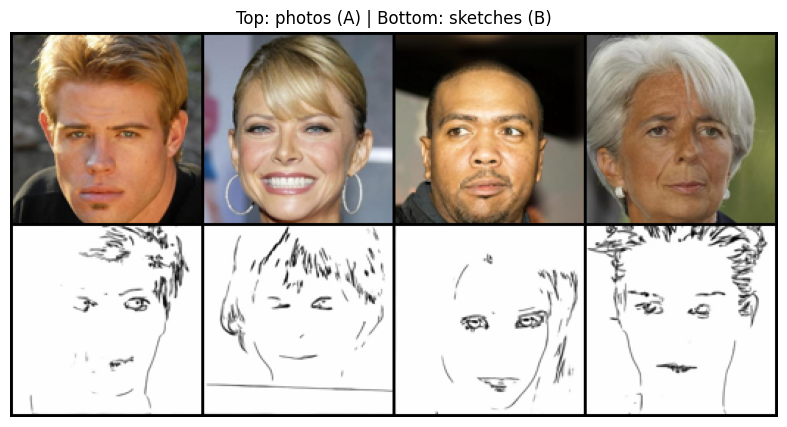

In [2]:
# ---- locate the dataset root and classify by the photos/sketches subfolder names ----
DATA_ROOT = '/kaggle/input/datasets/almightyj/person-face-sketches'
if not os.path.exists(DATA_ROOT):
    for d, dirs, _ in os.walk('/kaggle/input'):
        if 'person-face-sketches' in os.path.basename(d):
            DATA_ROOT = d; break
print('DATA_ROOT =', DATA_ROOT)
for d, dirs, fs in os.walk(DATA_ROOT):          # show folder structure
    if fs: print(os.path.relpath(d, DATA_ROOT), '->', len(fs), 'files')

EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
def collect(split_name):
    A, B = [], []
    for d, _, fs in os.walk(DATA_ROOT):
        rel = os.path.relpath(d, DATA_ROOT).lower().replace('\\', '/')
        parts = rel.split('/')
        if split_name is not None and split_name not in parts: continue
        for f in fs:
            if not f.lower().endswith(EXTS): continue
            p = os.path.join(d, f)
            if any('sketch' in x for x in parts): B.append(p)
            elif any('photo' in x for x in parts): A.append(p)
    return sorted(A), sorted(B)

trainA, trainB = collect('train')
testA,  testB  = collect('test')
if len(trainA) == 0 or len(trainB) == 0:        # no 'train' folder -> use everything and split 95/5
    allA, allB = collect(None)
    def split(files, frac=0.05):
        files = files[:]; random.shuffle(files); n = max(1, int(len(files) * frac))
        return files[n:], files[:n]
    trainA, testA = split(allA); trainB, testB = split(allB)
print(f'Found -> Train photos/sketches: {len(trainA)}/{len(trainB)} | Test: {len(testA)}/{len(testB)}')
assert len(trainA) > 0 and len(trainB) > 0, 'Check the folder listing printed above'

# ---- optional subsampling: the full set is ~22k per domain, far too slow for Kaggle's time limit ----
MAX_TRAIN = 3000                                 # images per domain per epoch pool (set None to use all)
if MAX_TRAIN:
    random.shuffle(trainA); random.shuffle(trainB)
    trainA, trainB = trainA[:MAX_TRAIN], trainB[:MAX_TRAIN]
testA, testB = testA[:200], testB[:200]
print(f'Using -> Train A/B: {len(trainA)}/{len(trainB)} | Test A/B: {len(testA)}/{len(testB)}')

train_tf = T.Compose([
    T.Resize(int(IMG_SIZE * 1.12), T.InterpolationMode.BICUBIC),
    T.RandomCrop(IMG_SIZE), T.RandomHorizontalFlip(),
    T.ToTensor(), T.Normalize((0.5,)*3, (0.5,)*3)])
test_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE), T.InterpolationMode.BICUBIC),
    T.ToTensor(), T.Normalize((0.5,)*3, (0.5,)*3)])

class UnpairedDS(Dataset):
    def __init__(self, a, b, tf, random_pair=True):
        self.a, self.b, self.tf, self.rp = a, b, tf, random_pair
    def __len__(self): return max(len(self.a), len(self.b))
    def __getitem__(self, i):
        fa = self.a[i % len(self.a)]
        fb = self.b[random.randrange(len(self.b))] if self.rp else self.b[i % len(self.b)]
        A = self.tf(Image.open(fa).convert('RGB')); B = self.tf(Image.open(fb).convert('RGB'))
        return A, B

train_loader = DataLoader(UnpairedDS(trainA, trainB, train_tf), batch_size=BATCH,
                          shuffle=True, num_workers=2, drop_last=True, pin_memory=True)
test_loader  = DataLoader(UnpairedDS(testA, testB, test_tf, False), batch_size=4, shuffle=False)
fixed_A, fixed_B = next(iter(test_loader)); fixed_A, fixed_B = fixed_A.to(device), fixed_B.to(device)

a, b = next(iter(train_loader))
grid = make_grid(torch.cat([a[:4], b[:4]]) * 0.5 + 0.5, nrow=4)
plt.figure(figsize=(10, 5)); plt.imshow(grid.permute(1, 2, 0)); plt.axis('off')
plt.title('Top: photos (A) | Bottom: sketches (B)'); plt.show()

In [3]:
%%writefile /kaggle/working/models.py
import numpy as np, torch, torch.nn as nn, torchvision.transforms as T

class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.b = nn.Sequential(
            nn.ReflectionPad2d(1), nn.Conv2d(c, c, 3), nn.InstanceNorm2d(c), nn.ReLU(True),
            nn.ReflectionPad2d(1), nn.Conv2d(c, c, 3), nn.InstanceNorm2d(c))
    def forward(self, x): return x + self.b(x)

class Generator(nn.Module):
    """c7s1-64, d128, d256, R256 x n, u128, u64, c7s1-3"""
    def __init__(self, n_res=6, nf=64):
        super().__init__()
        L = [nn.ReflectionPad2d(3), nn.Conv2d(3, nf, 7), nn.InstanceNorm2d(nf), nn.ReLU(True)]
        c = nf
        for _ in range(2):
            L += [nn.Conv2d(c, c*2, 3, 2, 1), nn.InstanceNorm2d(c*2), nn.ReLU(True)]; c *= 2
        L += [ResBlock(c) for _ in range(n_res)]
        for _ in range(2):
            L += [nn.ConvTranspose2d(c, c//2, 3, 2, 1, output_padding=1), nn.InstanceNorm2d(c//2), nn.ReLU(True)]; c //= 2
        L += [nn.ReflectionPad2d(3), nn.Conv2d(c, 3, 7), nn.Tanh()]
        self.m = nn.Sequential(*L)
    def forward(self, x): return self.m(x)

class Discriminator(nn.Module):
    """70x70 PatchGAN: C64-C128-C256-C512 -> 1"""
    def __init__(self, nf=64):
        super().__init__()
        def blk(i, o, s, norm=True):
            l = [nn.Conv2d(i, o, 4, s, 1)]
            if norm: l.append(nn.InstanceNorm2d(o))
            l.append(nn.LeakyReLU(0.2, True)); return l
        self.m = nn.Sequential(*blk(3, nf, 2, False), *blk(nf, nf*2, 2), *blk(nf*2, nf*4, 2),
                               *blk(nf*4, nf*8, 1), nn.Conv2d(nf*8, 1, 4, 1, 1))
    def forward(self, x): return self.m(x)

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None: nn.init.zeros_(m.bias)

# ---------- inference helpers ----------
def load_generators(path, device):
    ck = torch.load(path, map_location=device)
    cfg = ck['config']
    G_AB, G_BA = Generator(cfg['n_res']).to(device), Generator(cfg['n_res']).to(device)
    G_AB.load_state_dict(ck['G_AB']); G_BA.load_state_dict(ck['G_BA'])
    return G_AB.eval(), G_BA.eval(), cfg['img']

@torch.no_grad()
def translate(G, img, size):
    tf = T.Compose([T.Resize((size, size)), T.ToTensor(), T.Normalize((0.5,)*3, (0.5,)*3)])
    dev = next(G.parameters()).device
    y = G(tf(img.convert('RGB')).unsqueeze(0).to(dev))[0].cpu() * 0.5 + 0.5
    return T.ToPILImage()(y.clamp(0, 1))

def is_sketch(img):
    """Heuristic: sketches are almost colourless with a mostly-white page."""
    a = np.asarray(img.convert('RGB').resize((128, 128))).astype(np.float32) / 255.
    mx, mn = a.max(2), a.min(2)
    sat = ((mx - mn) / (mx + 1e-6)).mean()
    white = (a.mean(2) > 0.85).mean()
    return bool(sat < 0.10 and white > 0.25)

Writing /kaggle/working/models.py


In [4]:
%%writefile /kaggle/working/models.py
import numpy as np, torch, torch.nn as nn, torchvision.transforms as T

class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.b = nn.Sequential(
            nn.ReflectionPad2d(1), nn.Conv2d(c, c, 3), nn.InstanceNorm2d(c), nn.ReLU(True),
            nn.ReflectionPad2d(1), nn.Conv2d(c, c, 3), nn.InstanceNorm2d(c))
    def forward(self, x): return x + self.b(x)

class Generator(nn.Module):
    """c7s1-64, d128, d256, R256 x n, u128, u64, c7s1-3"""
    def __init__(self, n_res=6, nf=64):
        super().__init__()
        L = [nn.ReflectionPad2d(3), nn.Conv2d(3, nf, 7), nn.InstanceNorm2d(nf), nn.ReLU(True)]
        c = nf
        for _ in range(2):
            L += [nn.Conv2d(c, c*2, 3, 2, 1), nn.InstanceNorm2d(c*2), nn.ReLU(True)]; c *= 2
        L += [ResBlock(c) for _ in range(n_res)]
        for _ in range(2):
            L += [nn.ConvTranspose2d(c, c//2, 3, 2, 1, output_padding=1), nn.InstanceNorm2d(c//2), nn.ReLU(True)]; c //= 2
        L += [nn.ReflectionPad2d(3), nn.Conv2d(c, 3, 7), nn.Tanh()]
        self.m = nn.Sequential(*L)
    def forward(self, x): return self.m(x)

class Discriminator(nn.Module):
    """70x70 PatchGAN: C64-C128-C256-C512 -> 1"""
    def __init__(self, nf=64):
        super().__init__()
        def blk(i, o, s, norm=True):
            l = [nn.Conv2d(i, o, 4, s, 1)]
            if norm: l.append(nn.InstanceNorm2d(o))
            l.append(nn.LeakyReLU(0.2, True)); return l
        self.m = nn.Sequential(*blk(3, nf, 2, False), *blk(nf, nf*2, 2), *blk(nf*2, nf*4, 2),
                               *blk(nf*4, nf*8, 1), nn.Conv2d(nf*8, 1, 4, 1, 1))
    def forward(self, x): return self.m(x)

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None: nn.init.zeros_(m.bias)

# ---------- inference helpers ----------
def load_generators(path, device):
    ck = torch.load(path, map_location=device)
    cfg = ck['config']
    G_AB, G_BA = Generator(cfg['n_res']).to(device), Generator(cfg['n_res']).to(device)
    G_AB.load_state_dict(ck['G_AB']); G_BA.load_state_dict(ck['G_BA'])
    return G_AB.eval(), G_BA.eval(), cfg['img']

@torch.no_grad()
def translate(G, img, size):
    tf = T.Compose([T.Resize((size, size)), T.ToTensor(), T.Normalize((0.5,)*3, (0.5,)*3)])
    dev = next(G.parameters()).device
    y = G(tf(img.convert('RGB')).unsqueeze(0).to(dev))[0].cpu() * 0.5 + 0.5
    return T.ToPILImage()(y.clamp(0, 1))

def is_sketch(img):
    """Heuristic: sketches are almost colourless with a mostly-white page."""
    a = np.asarray(img.convert('RGB').resize((128, 128))).astype(np.float32) / 255.
    mx, mn = a.max(2), a.min(2)
    sat = ((mx - mn) / (mx + 1e-6)).mean()
    white = (a.mean(2) > 0.85).mean()
    return bool(sat < 0.10 and white > 0.25)

Overwriting /kaggle/working/models.py


In [5]:
import sys; sys.path.insert(0, WORK)
import importlib, models; importlib.reload(models)
from models import Generator, Discriminator, init_weights

G_AB = Generator(N_RES).to(device); G_BA = Generator(N_RES).to(device)   # photo->sketch, sketch->photo
D_A  = Discriminator().to(device);  D_B  = Discriminator().to(device)    # D_A judges photos, D_B judges sketches
for m in (G_AB, G_BA, D_A, D_B): m.apply(init_weights)
print('G params: %.2fM | D params: %.2fM' % (sum(p.numel() for p in G_AB.parameters())/1e6,
                                             sum(p.numel() for p in D_A.parameters())/1e6))

G params: 7.84M | D params: 2.76M


In [6]:
mse, l1 = nn.MSELoss(), nn.L1Loss()          # LSGAN adversarial loss + L1 cycle/identity

class ImagePool:
    def __init__(self, size=50): self.size, self.imgs = size, []
    def query(self, batch):
        out = []
        for im in batch.detach():
            im = im.unsqueeze(0)
            if len(self.imgs) < self.size: self.imgs.append(im); out.append(im)
            elif random.random() > 0.5:
                i = random.randrange(self.size); out.append(self.imgs[i].clone()); self.imgs[i] = im
            else: out.append(im)
        return torch.cat(out)

opt_G  = torch.optim.Adam(itertools.chain(G_AB.parameters(), G_BA.parameters()), lr=LR, betas=(BETA1, BETA2))
opt_DA = torch.optim.Adam(D_A.parameters(), lr=LR, betas=(BETA1, BETA2))
opt_DB = torch.optim.Adam(D_B.parameters(), lr=LR, betas=(BETA1, BETA2))
lam = lambda e: 1.0 if e < DECAY_START else max(0.0, 1.0 - (e - DECAY_START) / float(EPOCHS - DECAY_START))
scheds = [torch.optim.lr_scheduler.LambdaLR(o, lam) for o in (opt_G, opt_DA, opt_DB)]
pool_A, pool_B = ImagePool(POOL_SIZE), ImagePool(POOL_SIZE)

CKPT_LAST = f'{CKPT_DIR}/last.pth'
GEN_ONLY  = f'{WORK}/generators.pth'         # lightweight file used by the Flask app
CONFIG = {'img': IMG_SIZE, 'n_res': N_RES}
history, start_epoch = [], 0

def save_checkpoint(epoch):
    ck = {'epoch': epoch, 'config': CONFIG, 'history': history,
          'G_AB': G_AB.state_dict(), 'G_BA': G_BA.state_dict(),
          'D_A': D_A.state_dict(), 'D_B': D_B.state_dict(),
          'opt_G': opt_G.state_dict(), 'opt_DA': opt_DA.state_dict(), 'opt_DB': opt_DB.state_dict(),
          'sched': [s.state_dict() for s in scheds]}
    torch.save(ck, CKPT_LAST + '.tmp'); os.replace(CKPT_LAST + '.tmp', CKPT_LAST)
    gen = {'config': CONFIG, 'G_AB': G_AB.state_dict(), 'G_BA': G_BA.state_dict()}
    torch.save(gen, GEN_ONLY)
    if (epoch + 1) % 5 == 0:                 # keep a copy every 5 epochs to save disk space
        torch.save(gen, f'{CKPT_DIR}/gen_epoch_{epoch+1:03d}.pth')

if os.path.exists(CKPT_LAST):                # ---- auto-resume ----
    ck = torch.load(CKPT_LAST, map_location=device, weights_only=False)   # your own file, safe to load
    G_AB.load_state_dict(ck['G_AB']); G_BA.load_state_dict(ck['G_BA'])
    D_A.load_state_dict(ck['D_A']);   D_B.load_state_dict(ck['D_B'])
    opt_G.load_state_dict(ck['opt_G']); opt_DA.load_state_dict(ck['opt_DA']); opt_DB.load_state_dict(ck['opt_DB'])
    for s, sd in zip(scheds, ck['sched']): s.load_state_dict(sd)
    # convert numpy numbers to plain Python so future checkpoints load cleanly
    history = [{k: (int(v) if k == 'epoch' else float(v)) for k, v in h.items()} for h in ck['history']]
    start_epoch = ck['epoch'] + 1
    print(f'Resumed from epoch {start_epoch}')
else:
    print('No checkpoint found - starting from scratch')

No checkpoint found - starting from scratch


In [7]:
@torch.no_grad()
def save_samples(epoch):
    G_AB.eval(); G_BA.eval()
    fB, fA = G_AB(fixed_A), G_BA(fixed_B)
    rA, rB = G_BA(fB), G_AB(fA)
    grid = torch.cat([fixed_A, fB, rA, fixed_B, fA, rB]) * 0.5 + 0.5
    save_image(grid, f'{SAMPLE_DIR}/epoch_{epoch+1:03d}.png', nrow=fixed_A.size(0))
    G_AB.train(); G_BA.train()

for epoch in range(start_epoch, EPOCHS):
    t0 = time.time(); agg = np.zeros(4); n = 0
    for real_A, real_B in train_loader:
        real_A, real_B = real_A.to(device), real_B.to(device)

        # ---------- Generators ----------
        opt_G.zero_grad()
        loss_id = (l1(G_BA(real_A), real_A) + l1(G_AB(real_B), real_B)) * LAMBDA_ID
        fake_B, fake_A = G_AB(real_A), G_BA(real_B)
        pB, pA = D_B(fake_B), D_A(fake_A)
        loss_gan = mse(pB, torch.ones_like(pB)) + mse(pA, torch.ones_like(pA))
        loss_cyc = (l1(G_BA(fake_B), real_A) + l1(G_AB(fake_A), real_B)) * LAMBDA_CYC
        loss_G = loss_gan + loss_cyc + loss_id
        loss_G.backward(); opt_G.step()

        # ---------- Discriminator A (photos) ----------
        opt_DA.zero_grad()
        pr, pf = D_A(real_A), D_A(pool_A.query(fake_A))
        loss_DA = 0.5 * (mse(pr, torch.ones_like(pr)) + mse(pf, torch.zeros_like(pf)))
        loss_DA.backward(); opt_DA.step()

        # ---------- Discriminator B (sketches) ----------
        opt_DB.zero_grad()
        pr, pf = D_B(real_B), D_B(pool_B.query(fake_B))
        loss_DB = 0.5 * (mse(pr, torch.ones_like(pr)) + mse(pf, torch.zeros_like(pf)))
        loss_DB.backward(); opt_DB.step()

        agg += [loss_G.item(), loss_gan.item(), loss_cyc.item(), (loss_DA + loss_DB).item()]; n += 1

    for s in scheds: s.step()
    agg /= max(n, 1)
    history.append({'epoch': epoch + 1, 'G': float(agg[0]), 'GAN': float(agg[1]), 'cycle': float(agg[2]), 'D': float(agg[3])})
    save_checkpoint(epoch)          # <-- saved every epoch
    save_samples(epoch)
    print(f'Epoch {epoch+1:3d}/{EPOCHS} | G {agg[0]:.3f} (GAN {agg[1]:.3f}, cyc {agg[2]:.3f}) | '
          f'D {agg[3]:.3f} | lr {opt_G.param_groups[0]["lr"]:.2e} | {time.time()-t0:.0f}s')

Epoch   1/50 | G 5.440 (GAN 0.963, cyc 3.113) | D 0.607 | lr 2.00e-04 | 350s
Epoch   2/50 | G 4.301 (GAN 0.945, cyc 2.370) | D 0.398 | lr 2.00e-04 | 353s
Epoch   3/50 | G 4.044 (GAN 0.975, cyc 2.190) | D 0.353 | lr 2.00e-04 | 353s
Epoch   4/50 | G 3.884 (GAN 0.988, cyc 2.081) | D 0.335 | lr 2.00e-04 | 354s
Epoch   5/50 | G 3.778 (GAN 1.022, cyc 1.985) | D 0.305 | lr 2.00e-04 | 354s
Epoch   6/50 | G 3.647 (GAN 0.999, cyc 1.914) | D 0.311 | lr 2.00e-04 | 354s
Epoch   7/50 | G 3.628 (GAN 1.073, cyc 1.852) | D 0.288 | lr 2.00e-04 | 354s
Epoch   8/50 | G 3.521 (GAN 1.023, cyc 1.811) | D 0.292 | lr 2.00e-04 | 354s
Epoch   9/50 | G 3.554 (GAN 1.108, cyc 1.777) | D 0.325 | lr 2.00e-04 | 354s
Epoch  10/50 | G 3.391 (GAN 1.087, cyc 1.670) | D 0.261 | lr 2.00e-04 | 354s
Epoch  11/50 | G 3.445 (GAN 1.146, cyc 1.670) | D 0.246 | lr 2.00e-04 | 354s
Epoch  12/50 | G 3.590 (GAN 1.354, cyc 1.624) | D 0.183 | lr 2.00e-04 | 354s
Epoch  13/50 | G 3.308 (GAN 1.169, cyc 1.548) | D 0.251 | lr 2.00e-04 | 355s

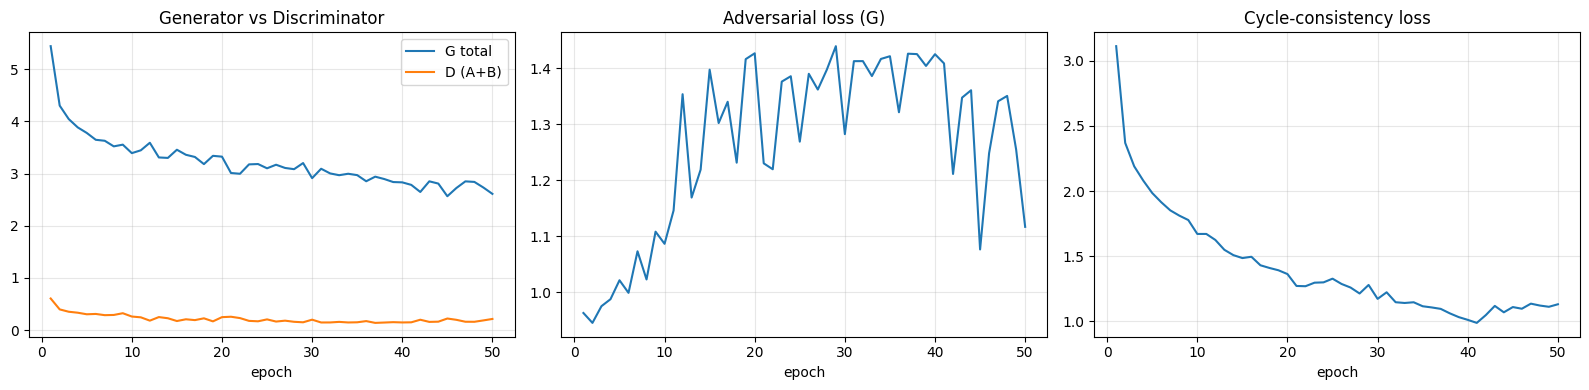

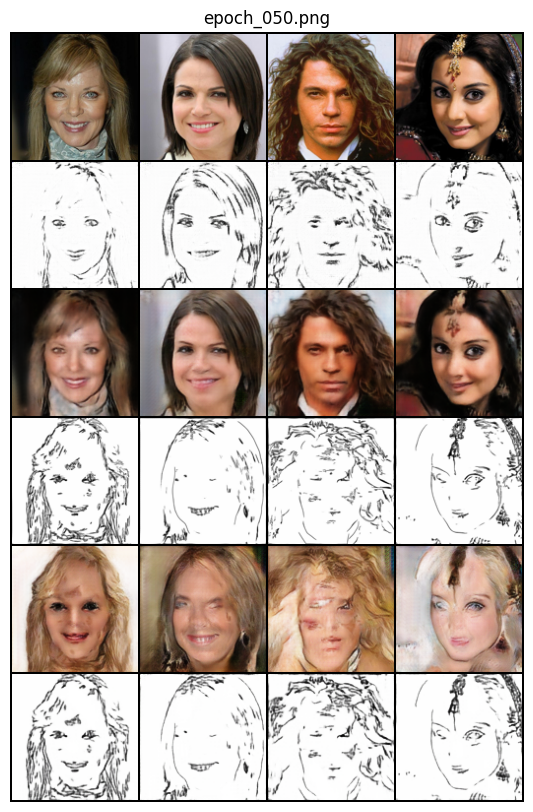

In [8]:
import pandas as pd
df = pd.DataFrame(history)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(df.epoch, df.G, label='G total'); ax[0].plot(df.epoch, df.D, label='D (A+B)'); ax[0].legend(); ax[0].set_title('Generator vs Discriminator')
ax[1].plot(df.epoch, df.GAN); ax[1].set_title('Adversarial loss (G)')
ax[2].plot(df.epoch, df.cycle); ax[2].set_title('Cycle-consistency loss')
for a in ax: a.set_xlabel('epoch'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Rows: photo | ->sketch | cycle-rec | sketch | ->photo | cycle-rec
last = sorted(glob.glob(f'{SAMPLE_DIR}/*.png'))[-1]
plt.figure(figsize=(12, 10)); plt.imshow(Image.open(last)); plt.axis('off'); plt.title(os.path.basename(last)); plt.show()

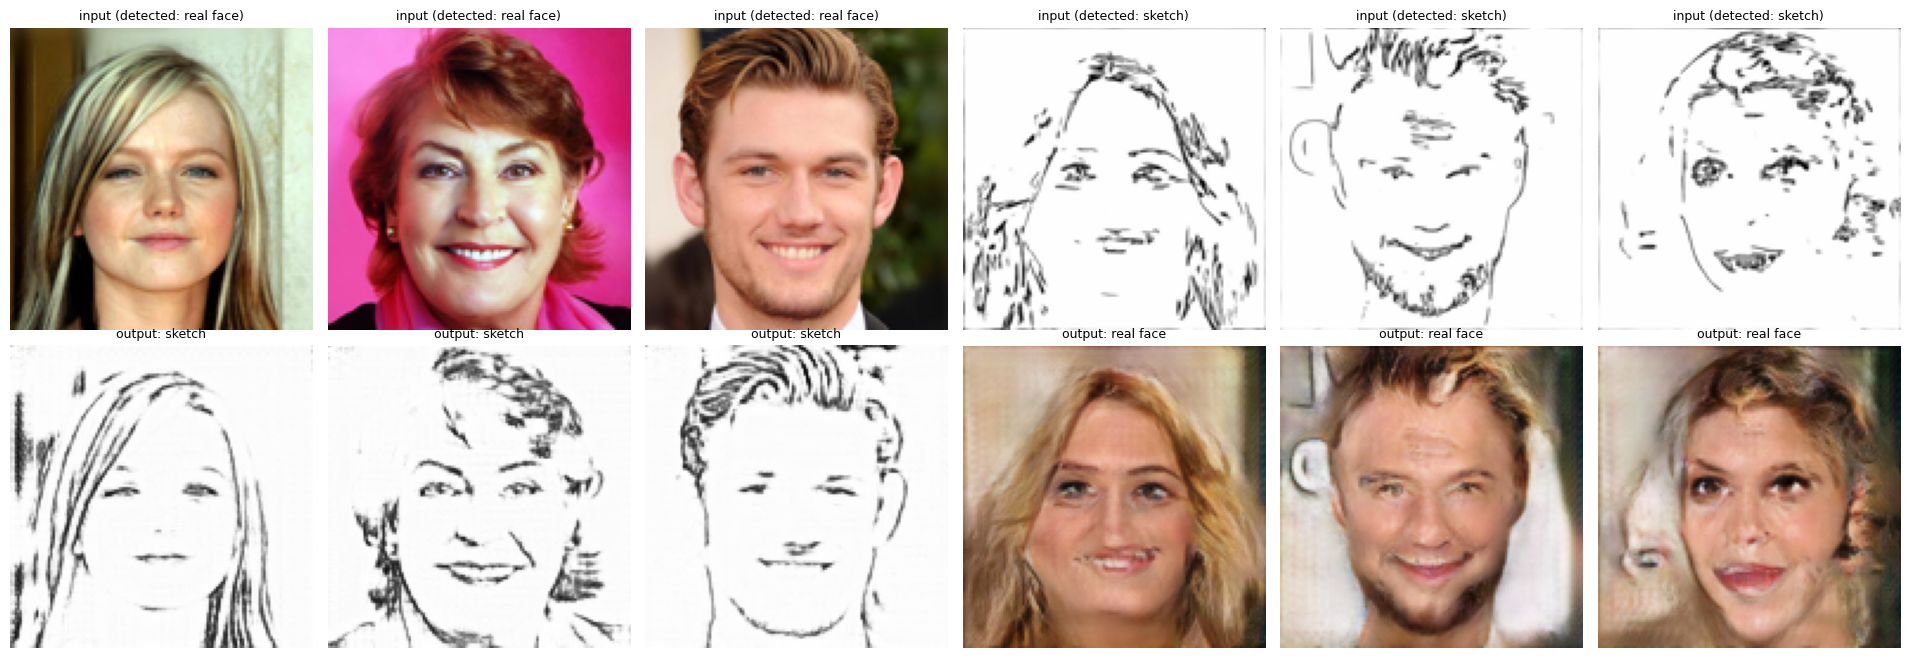

Detector accuracy  photos: 99.50% | sketches: 100.00%


In [9]:
from models import load_generators, translate, is_sketch
G_AB_i, G_BA_i, size = load_generators(GEN_ONLY, device)

def convert(img):
    """Auto-detect: sketch -> real face, real face -> sketch."""
    if is_sketch(img): return 'sketch', 'real face', translate(G_BA_i, img, size)
    return 'real face', 'sketch', translate(G_AB_i, img, size)

samples = random.sample(testA, min(3, len(testA))) + random.sample(testB, min(3, len(testB)))
fig, ax = plt.subplots(2, len(samples), figsize=(3.2*len(samples), 6.6))
for i, p in enumerate(samples):
    im = Image.open(p).convert('RGB'); src, dst, out = convert(im)
    ax[0, i].imshow(im.resize((size, size))); ax[0, i].set_title(f'input (detected: {src})', fontsize=9)
    ax[1, i].imshow(out); ax[1, i].set_title(f'output: {dst}', fontsize=9)
    ax[0, i].axis('off'); ax[1, i].axis('off')
plt.tight_layout(); plt.show()

acc_A = np.mean([not is_sketch(Image.open(p)) for p in testA])
acc_B = np.mean([is_sketch(Image.open(p)) for p in testB])
print(f'Detector accuracy  photos: {acc_A:.2%} | sketches: {acc_B:.2%}')

In [10]:
%%writefile /kaggle/working/app.py
import io, base64, os, torch
from flask import Flask, request, jsonify, Response
from PIL import Image
from models import load_generators, translate, is_sketch

HERE = os.path.dirname(os.path.abspath(__file__))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
G_AB, G_BA, SIZE = load_generators(os.path.join(HERE, 'generators.pth'), device)
app = Flask(__name__)

def b64(img):
    buf = io.BytesIO(); img.save(buf, 'PNG'); return base64.b64encode(buf.getvalue()).decode()

HTML = """<!doctype html><html><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>CycleGAN Face <-> Sketch</title>
<style>
body{font-family:system-ui,sans-serif;background:#0f172a;color:#e2e8f0;margin:0;padding:24px;text-align:center}
h1{margin:0 0 4px}p.sub{color:#94a3b8;margin-top:0}
.card{background:#1e293b;border-radius:14px;padding:18px;max-width:900px;margin:16px auto}
button,select{background:#6366f1;color:#fff;border:0;border-radius:8px;padding:10px 16px;margin:4px;font-size:15px;cursor:pointer}
select{background:#334155}input[type=file]{display:none}
.row{display:flex;gap:16px;justify-content:center;flex-wrap:wrap}
.box{flex:1;min-width:260px}.box img,video{width:100%;max-width:340px;border-radius:10px;background:#0b1220;min-height:120px}
#status{margin:10px;color:#a5b4fc;min-height:22px}
</style></head><body>
<h1>Face &harr; Sketch (CycleGAN)</h1>
<p class="sub">Upload a picture or use your camera. The app detects whether it is a sketch or a real face and converts it.</p>
<div class="card">
  <button onclick="document.getElementById('f').click()">Upload image</button>
  <input id="f" type="file" accept="image/*">
  <button onclick="startCam()">Use camera</button>
  <button id="snap" onclick="snap()" style="display:none">Capture &amp; convert</button>
  <select id="mode"><option value="auto">Auto-detect</option><option value="photo">Force: input is a photo</option><option value="sketch">Force: input is a sketch</option></select>
  <div><video id="v" autoplay playsinline style="display:none"></video><canvas id="c" style="display:none"></canvas></div>
  <div id="status"></div>
  <div class="row">
    <div class="box"><h3 id="t1">Input</h3><img id="in"></div>
    <div class="box"><h3 id="t2">Output</h3><img id="out"></div>
  </div>
</div>
<script>
const $=id=>document.getElementById(id);
async function send(blob){
  $('status').textContent='Converting...';
  $('in').src=URL.createObjectURL(blob);
  const fd=new FormData(); fd.append('image',blob,'img.png'); fd.append('mode',$('mode').value);
  try{
    const r=await fetch('/convert',{method:'POST',body:fd}); const j=await r.json();
    if(j.error){$('status').textContent=j.error;return;}
    $('out').src='data:image/png;base64,'+j.output;
    $('t1').textContent='Input (detected: '+j.detected+')'; $('t2').textContent='Output ('+j.target+')';
    $('status').textContent='Done';
  }catch(e){$('status').textContent='Request failed: '+e;}
}
$('f').onchange=e=>{if(e.target.files[0])send(e.target.files[0]);};
async function startCam(){
  try{const s=await navigator.mediaDevices.getUserMedia({video:true});
    $('v').srcObject=s;$('v').style.display='inline-block';$('snap').style.display='inline-block';}
  catch(e){$('status').textContent='Camera unavailable (needs HTTPS and permission).';}
}
function snap(){
  const v=$('v'),c=$('c');c.width=v.videoWidth;c.height=v.videoHeight;
  c.getContext('2d').drawImage(v,0,0);c.toBlob(b=>send(b),'image/png');
}
</script></body></html>"""

@app.route('/')
def index(): return Response(HTML, mimetype='text/html')

@app.route('/convert', methods=['POST'])
def convert():
    if 'image' not in request.files: return jsonify(error='No image received')
    try: img = Image.open(request.files['image'].stream).convert('RGB')
    except Exception: return jsonify(error='Could not read the image')
    mode = request.form.get('mode', 'auto')
    sketch = is_sketch(img) if mode == 'auto' else (mode == 'sketch')
    out = translate(G_BA if sketch else G_AB, img, SIZE).resize((256, 256), Image.BICUBIC)
    return jsonify(output=b64(out), detected='sketch' if sketch else 'real face',
                   target='real face' if sketch else 'sketch')

if __name__ == '__main__':
    app.run(host='0.0.0.0', port=5000)

Writing /kaggle/working/app.py


In [11]:
!pip -q install flask pyngrok

import os, threading, socket, time
from pyngrok import ngrok
from kaggle_secrets import UserSecretsClient

# 1) make sure the trained weights exist (the app loads them at startup)
assert os.path.exists('/kaggle/working/generators.pth'), 'generators.pth not found - train first (Cell 5)'
assert os.path.exists('/kaggle/working/app.py'), 'app.py not found - run Cell 8 first'

# 2) get the ngrok token from Kaggle Secrets (label: NGROK_TOKEN)
NGROK_TOKEN = UserSecretsClient().get_secret("NGROK_TOKEN").strip().split()[0]
ngrok.set_auth_token(NGROK_TOKEN)

# 3) start Flask only if port 5000 is free
import app as webapp
s = socket.socket(); busy = s.connect_ex(('127.0.0.1', 5000)) == 0; s.close()
if not busy:
    threading.Thread(target=lambda: webapp.app.run(host='0.0.0.0', port=5000, use_reloader=False),
                     daemon=True).start()
    time.sleep(2)

# 4) open the public HTTPS tunnel
ngrok.kill()
public_url = ngrok.connect(5000).public_url
print('Open the demo here ->', public_url)

 * Serving Flask app 'app'
 * Debug mode: off


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.19.2.2:5000
Press CTRL+C to quit


Open the demo here -> https://dislike-scheming-directed.ngrok-free.dev
